In [2]:
%matplotlib inline
import scrublet as scr
import scipy.io
import matplotlib.pyplot as plt
import numpy as np
import os

In [3]:
#Load data
input_dir = '../rna_d5/outs/filtered_feature_bc_matrix/'
counts_matrix = scipy.io.mmread(input_dir + 'matrix.mtx.gz').T.tocsc()
genes = np.array(scr.load_genes('permissionFiles/features_d5_genes.tsv', delimiter='\t', column=1))
# print(counts_matrix)
print('Counts matrix shape: {} rows, {} columns'.format(counts_matrix.shape[0], counts_matrix.shape[1]))
print('Number of genes in gene list: {}'.format(len(genes)))

Counts matrix shape: 8515 rows, 31053 columns
Number of genes in gene list: 31053


In [4]:
# calculate
scrub = scr.Scrublet(counts_matrix, expected_doublet_rate=0.06)

In [5]:
doublet_scores, predicted_doublets = scrub.scrub_doublets(min_counts=2, 
                                                          min_cells=3, 
                                                          min_gene_variability_pctl=85, 
                                                          n_prin_comps=30)

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.65
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 0.4%
Overall doublet rate:
	Expected   = 6.0%
	Estimated  = 8.8%
Elapsed time: 27.4 seconds


Detected doublet rate = 1.2%
Estimated detectable doublet fraction = 16.2%
Overall doublet rate:
	Expected   = 6.0%
	Estimated  = 7.4%


(<Figure size 576x216 with 2 Axes>,
 array([<matplotlib.axes._subplots.AxesSubplot object at 0x7f8abd452050>,
       dtype=object))

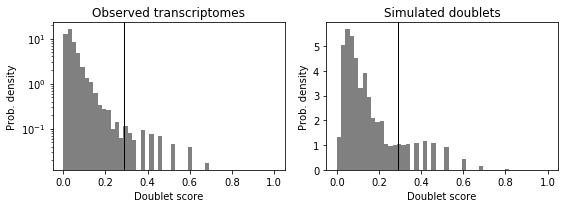

In [8]:
# plot
scrub.call_doublets(threshold=0.29) ## threshold from d3
scrub.plot_histogram()

In [10]:
# cluster view
print('Running UMAP...')
scrub.set_embedding('UMAP', scr.get_umap(scrub.manifold_obs_, 10, min_dist=0.3))
print('Done.')

Running UMAP...


/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/numba/compiler.py:602: NumbaPerformanceWarning: 
The keyword argument 'parallel=True' was specified but no transformation for parallel execution was possible.

To find out why, try turning on parallel diagnostics, see http://numba.pydata.org/numba-doc/latest/user/parallel.html#diagnostics for help.

File "../../.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/umap/nndescent.py", line 47:
    @numba.njit(parallel=True)
    def nn_descent(
    ^

  self.func_ir.loc))


Done.


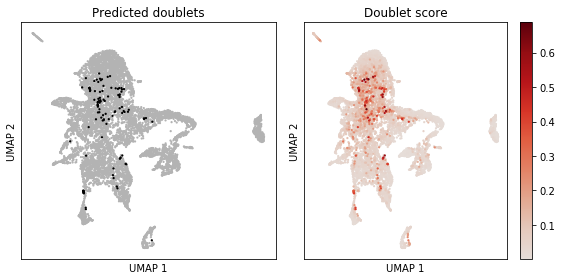

In [11]:
scrub.plot_embedding('UMAP', order_points=True);

In [12]:
# use mitochondria deleted data, unnormalized

import pandas as pd
d5mt = pd.read_csv('d5mt.csv')

In [13]:
d5mt

,Unnamed: 0,AAACCCAAGCTAAGTA,AAACCCACAACTTGGT,AAACCCACACAGAGCA,AAACCCAGTTACACAC,AAACCCAGTTCCGCAG,AAACCCATCCTTCTTC,AAACCCATCTTTGGAG,AAACGAAAGCAAATGT,AAACGAAAGCTGTTAC,...,TTTGTTGCAACTGTGT,TTTGTTGCAAGAGTTA,TTTGTTGCAGTGTGCC,TTTGTTGCATGGATCT,TTTGTTGGTATATGGA,TTTGTTGGTATCCTTT,TTTGTTGGTCCGGACT,TTTGTTGTCATCGGGC,TTTGTTGTCCAACCAA,TTTGTTGTCGTCCATC
0,Mrpl15,6,2,2,0,0,0,2,2,0,...,0,2,0,5,2,1,1,4,7,0
1,Lypla1,0,1,0,0,0,0,1,2,0,...,0,0,0,1,0,0,0,0,0,0
2,Gm37988,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Tcea1,0,4,0,0,2,0,2,0,1,...,0,2,0,3,1,0,0,1,1,1
4,Atp6v1h,1,0,0,0,0,1,0,0,0,...,0,1,0,2,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16046,AC168977.2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
16047,AC168977.1,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
16048,AC149090.1,1,2,1,2,1,1,0,0,0,...,0,3,1,3,2,2,0,4,5,1
16049,CAAA01118383.1,2,1,2,0,1,0,0,0,0,...,0,1,0,2,0,1,0,3,1,0


In [14]:
scrub = scr.Scrublet(scipy.sparse.csr_matrix(d5mt.iloc[:,1:].values.T), expected_doublet_rate=0.06)

In [15]:
doublet_scores, predicted_doublets = scrub.scrub_doublets(min_counts=2, 
                                                          min_cells=3, 
                                                          min_gene_variability_pctl=85, 
                                                          n_prin_comps=30)

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.64
Detected doublet rate = 0.1%
Estimated detectable doublet fraction = 0.8%
Overall doublet rate:
	Expected   = 6.0%
	Estimated  = 11.9%
Elapsed time: 16.6 seconds


Detected doublet rate = 1.2%
Estimated detectable doublet fraction = 19.6%
Overall doublet rate:
	Expected   = 6.0%
	Estimated  = 6.2%


(<Figure size 576x216 with 2 Axes>,
 array([<matplotlib.axes._subplots.AxesSubplot object at 0x7f8ab09074d0>,
       dtype=object))

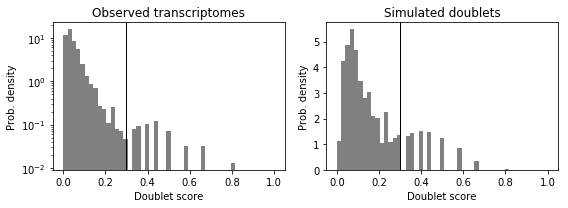

In [16]:
scrub.call_doublets(threshold=0.30)
scrub.plot_histogram()

Running UMAP...


/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/numba/compiler.py:602: NumbaPerformanceWarning: 
The keyword argument 'parallel=True' was specified but no transformation for parallel execution was possible.

To find out why, try turning on parallel diagnostics, see http://numba.pydata.org/numba-doc/latest/user/parallel.html#diagnostics for help.

File "../../.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/umap/nndescent.py", line 47:
    @numba.njit(parallel=True)
    def nn_descent(
    ^

  self.func_ir.loc))


Done.


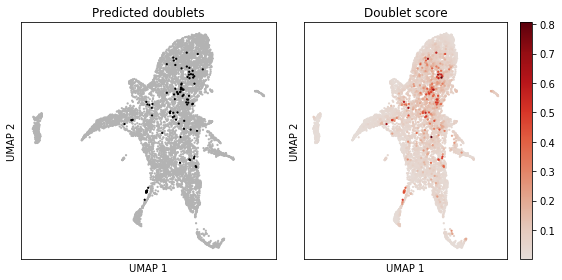

In [17]:
# cluster view
print('Running UMAP...')
scrub.set_embedding('UMAP', scr.get_umap(scrub.manifold_obs_, 10, min_dist=0.3))
print('Done.')
scrub.plot_embedding('UMAP', order_points=True);

In [18]:
df = pd.DataFrame({
    'barcodes': d5mt.columns[1:],
    'doublet_score': scrub.doublet_scores_obs_,
    'predicted_doublet': scrub.predicted_doublets_
})


df.to_csv('scrublet_d5.csv', index=False)

In [19]:
df

,barcodes,doublet_score,predicted_doublet
0,AAACCCAAGCTAAGTA,0.042238,False
1,AAACCCACAACTTGGT,0.027059,False
2,AAACCCACACAGAGCA,0.036392,False
3,AAACCCAGTTACACAC,0.015884,False
4,AAACCCAGTTCCGCAG,0.027059,False
...,...,...,...
7526,TTTGTTGGTATCCTTT,0.035330,False
7527,TTTGTTGGTCCGGACT,0.025486,False
7528,TTTGTTGTCATCGGGC,0.124563,False
7529,TTTGTTGTCCAACCAA,0.047676,False
